<a href="https://colab.research.google.com/github/samuelroagarrido/mi-dashboard-ventas/blob/main/Taller_Graficos_Publicacion_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1. Mariana Silva
 2. Emiliana Sepúlveda
 3. Samuel Roa
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [117]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (2).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [118]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

Text(0.5, 0, 'Ingresos (pesos)')

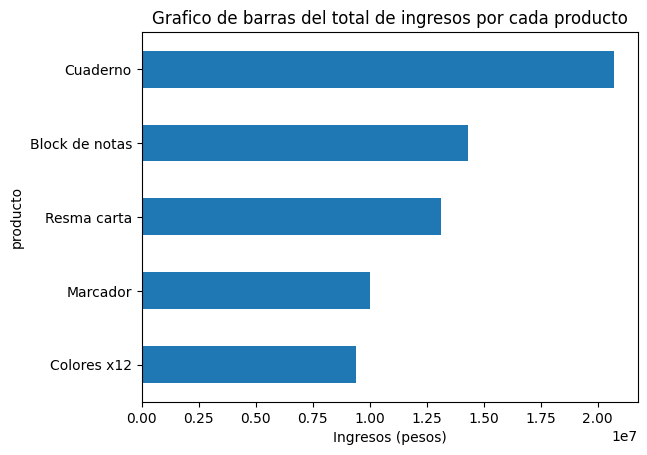

In [119]:
# Ejercicio 1
# Agrupa las ventas por producto, suma el total de cada uno,
# ordena de mayor a menor y se queda solo con los 5 primeros.
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
  # groupby("producto")["total"]: agrupa las ventas por producto y mira la columna total
  # .sum(): suma el dinero de cada producto
  # .sort_values(ascending=False): ordena de mayor a menor (los que más venden primero)
  # .head(5): se queda solo con los 5 primeros
top_productos.sort_values().plot.barh(title = "Grafico de barras del total de ingresos por cada producto")
  # Dibuja barras horizontales.
  # El sort_values() extra pone el mayor ARRIBA, porque barh dibuja de abajo hacia arriba.
plt.xlabel("Ingresos (pesos)")
  # Variable del eje x

In [120]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

Text(0, 0.5, 'Ingresos (pesos)')

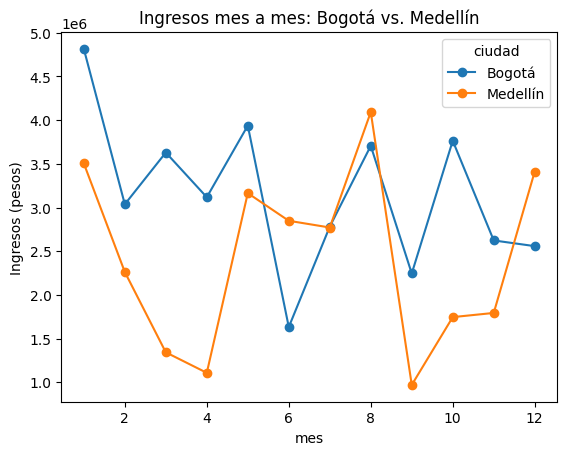

In [121]:
# Ejercicio 2
bogota_medellin = df[df["ciudad"].isin(["Bogotá" , "Medellín"])]
# isin: se queda solo con las filas cuya ciudad esté en la lista
ing_mes_ciudad = pd.pivot_table(bogota_medellin, index = "mes", columns = "ciudad", values= "total", aggfunc = "sum")
# pivot_table: index = filas (meses), columns = una columna por ciudad,
# values = qué se calcula, aggfunc = cómo (suma). No usar reset_index()
ing_mes_ciudad.shape  # comprobación: debe dar (12, 2)
ing_mes_ciudad.plot.line(marker="o", title = "Ingresos mes a mes: Bogotá vs. Medellín")
# plot.line: una línea por ciudad; marker="o" pone un punto en cada mes
plt.ylabel("Ingresos (pesos)")
# Variable eje y

In [122]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

<Axes: title={'center': '¿Por qué canal se vende más?'}>

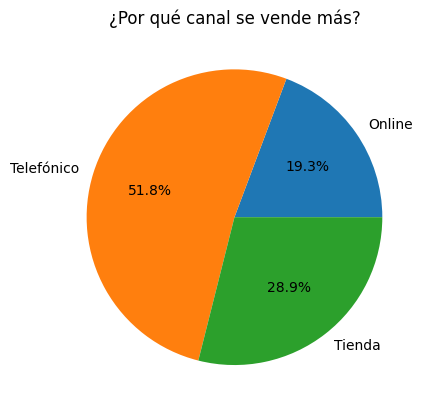

In [123]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()
# Suma el dinero de cada canal
ing_canal.plot.pie(autopct="%1.1f%%", ylabel="", title="¿Por qué canal se vende más?")
# Gráfico de pie con porcentajes de 1 decimal

In [124]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

Text(0, 0.5, 'Porcentaje')

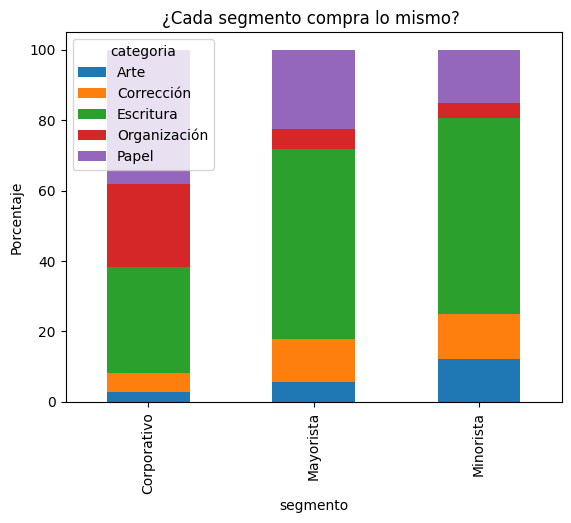

In [125]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(df["segmento"],df["categoria"], normalize = "index") * 100
# crosstab: cuenta las ventas por segmento (filas) y categoría (columnas)
# normalize="index" hace que cada fila sume 1; * 100 lo pasa a porcentaje
tabla_seg_cat.sum(axis=1) #comprobación
tabla_seg_cat.plot.bar(stacked=True, title = "¿Cada segmento compra lo mismo? ")
#Crea la gráfica de barras apiladas
plt.ylabel("Porcentaje")
# Variable eje y

In [126]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

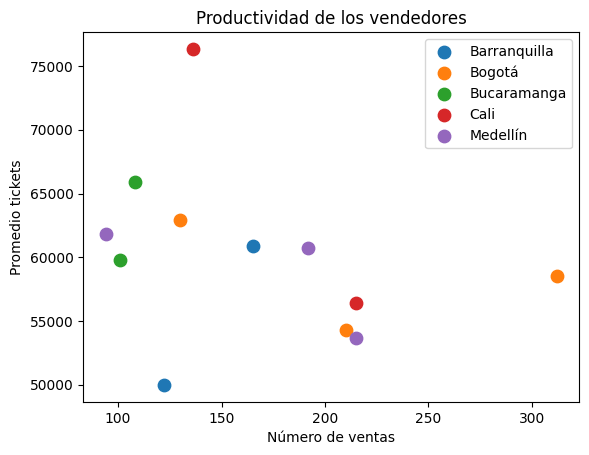

In [127]:
# Ejercicio 5
vend = (df.groupby(["vendedor", "ciudad"]).agg(n_ventas = ("total","count"), ticket_prom = ("total","mean")).reset_index())
# groupby con 2 columnas: un grupo por vendedor y ciudad
# agg: calcula dos cosas a la vez: n_ventas (cuenta) y ticket_prom (promedio)
# reset_index(): vendedor y ciudad quedan como columnas normales
vend.shape # comprobación debe dar (12, 4)
for ciudad, grupo in vend.groupby("ciudad"): # El for dibuja una ciudad por vuelta, así cada ciudad tiene su color
  plt.scatter(grupo["n_ventas"], grupo["ticket_prom"],label=ciudad, s=80)
   # X = n_ventas, Y = ticket_prom, s = tamaño del punto
plt.xlabel("Número de ventas")
plt.ylabel("Promedio tickets")
plt.title("Productividad de los vendedores")
plt.legend() # va afuera del for para que salga una sola vez

In [128]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

Text(0, 0.5, 'Valor de la venta (pesos)')

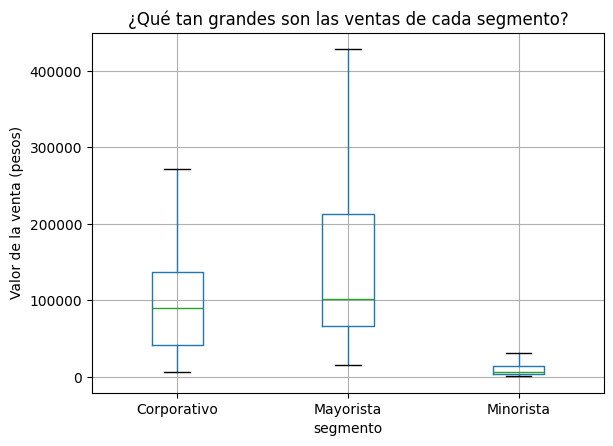

In [129]:
# Ejercicio 6
sem2 = df[df["mes"] >= 7] # segundo semestre: meses 7 a 12
len(sem2) # comprobación: 1050
sem2.boxplot(column="total", by="segmento", showfliers=False)
# una caja por segmento, sin extremos
plt.suptitle("") # borra el título automático feo
plt.title("¿Qué tan grandes son las ventas de cada segmento?")
plt.ylabel("Valor de la venta (pesos)") # Variable eje y

In [130]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [131]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3

# Crea la cuadrícula de 2 filas y 3 columnas
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Fila 0
top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Gráfico de barras del total de ingresos por cada producto")   # casilla 0,0
axs[0, 0].set_xlabel("Ingresos (pesos)")
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mes a mes: Bogotá vs. Medellín")   # casilla 0,1
ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", ylabel="", title="¿Por qué canal se vende más?")   # casilla 0,2

# Fila 1
tabla_seg_cat.plot.bar(stacked=True, ax=axs[1, 0], title="¿Cada segmento compra lo mismo?")   # casilla 1,0

# Dispersión en la casilla 1,1: un color por ciudad
for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, s=80)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Promedio tickets")
axs[1, 1].set_title("Productividad de los vendedores")
axs[1, 1].legend()

# Cajas en la casilla 1,2
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=axs[1, 2])
axs[1, 2].set_title("¿Qué tan grandes son las ventas de cada segmento?")

# Título general y ajuste de espacios (van al final)
fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout()

Overwriting figura_base.py


In [132]:
%run -i figura_base.py

In [133]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [134]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: código de la figura 2x3

# Crea la cuadrícula de 2 filas y 3 columnas
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Fila 0
top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Gráfico de barras del total de ingresos por cada producto")   # casilla 0,0
axs[0, 0].set_xlabel("Ingresos (pesos)")
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mes a mes: Bogotá vs. Medellín")   # casilla 0,1
ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", ylabel="", title="¿Por qué canal se vende más?")   # casilla 0,2

# Fila 1
tabla_seg_cat.plot.bar(stacked=True, ax=axs[1, 0], title="¿Cada segmento compra lo mismo?")   # casilla 1,0

# Dispersión en la casilla 1,1: un color por ciudad
for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, s=80)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Promedio tickets")
axs[1, 1].set_title

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [135]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La figura será presentada a la gerente de compras o a la dirección regional. Su propósito es facilitar la toma de decisiones estratégicas sobre el desempeño de las cinco ciudades, identificar cuáles requieren mayor atención y definir dónde priorizar compras, recursos o acciones de mejora.

PALETA Y TIPOGRAFÍA: Utiliza un diseño profesional, moderno y ejecutivo, con fondo gris muy claro y paneles blancos. Usa un color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Estos colores solo se usan en el gráfico de líneas y en la dispersión; en los otros cuatro gráficos usa una paleta neutra (grises y azules suaves) que no coincida con los colores de ciudad. Fuente sans-serif; títulos en negrita y alineados a la izquierda. Tamaños: títulos de los gráficos 14, etiquetas de ejes 11, valores sobre las barras 10 y título general 18.

TÍTULOS: Cada gráfico debe tener un título que comunique su principal conclusión, en lugar de limitarse a describir la variable. Los títulos deben ser breves y directos. Datos que ya verifiqué: Cuaderno es el producto con más ingresos y el canal Telefónico concentra más de la mitad de los ingresos. Basa los títulos solo en lo que muestran las tablas y no inventes cifras ni conclusiones.

EJES Y NÚMEROS: Usa etiquetas de ejes claras, legibles y fáciles de interpretar. Muestra los valores monetarios en pesos con formato compacto (por ejemplo, "$ 20 M") y separador de miles.

LIMPIEZA VISUAL: Elimina los bordes superior y derecho de los gráficos. Utiliza líneas de cuadrícula suaves y discretas, muestra los valores directamente sobre las barras cuando corresponda y presenta las leyendas sin marco. Evita elementos decorativos innecesarios, saturación de colores y textos que dificulten la lectura.

ENFOQUE EJECUTIVO: Prioriza la claridad, la comparación entre ciudades y la identificación rápida de oportunidades, diferencias y aspectos que requieren atención. La figura debe permitir tomar decisiones sin necesidad de interpretaciones adicionales.

INSTRUCCIONES FINALES OBLIGATORIAS:
Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo."""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO: La figura será presentada a la gerente de compras o a la dirección regional. Su propósito es facilitar la toma de decisiones estratégicas sobre el desempeño de las cinco ciudades, identificar cuáles requieren mayor atención y definir dónde priorizar compras, recursos o acciones de mejora.

PALETA Y TIPOGRAFÍA: Utiliza un diseño profesional, moderno y ejecutivo, con fondo gris muy claro y paneles blancos. Usa un color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Estos colores solo se usan en el gráfico de líneas y en la dispersión; en los otros cuatro gráficos usa una paleta neutra (grises y azules suaves) que no coincida con los colores de ciudad. Fuente sans-serif; títulos en negrita y alineados a la izquierda. Tamaños: títulos de los gráficos 14, etiquetas de ejes 11, valores sobre las barras 10 y título general 18.

TÍTULOS: Cada gráfico debe tener un título que comunique su principal conclusión, 

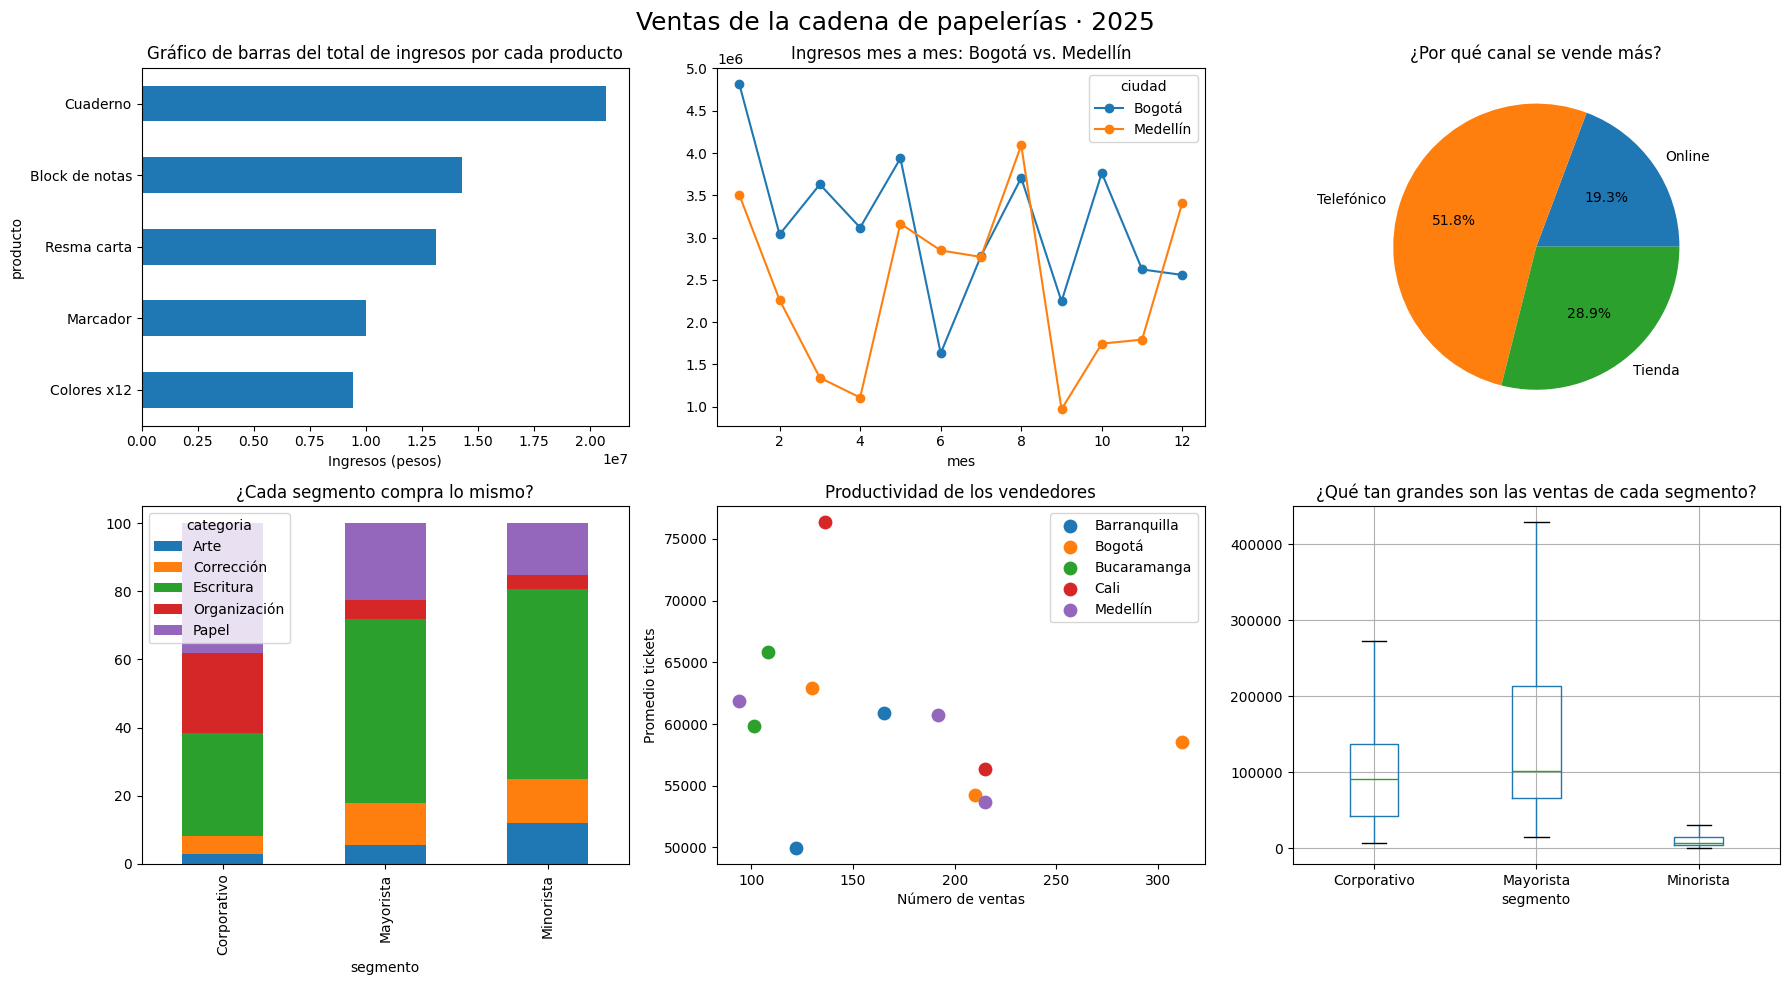

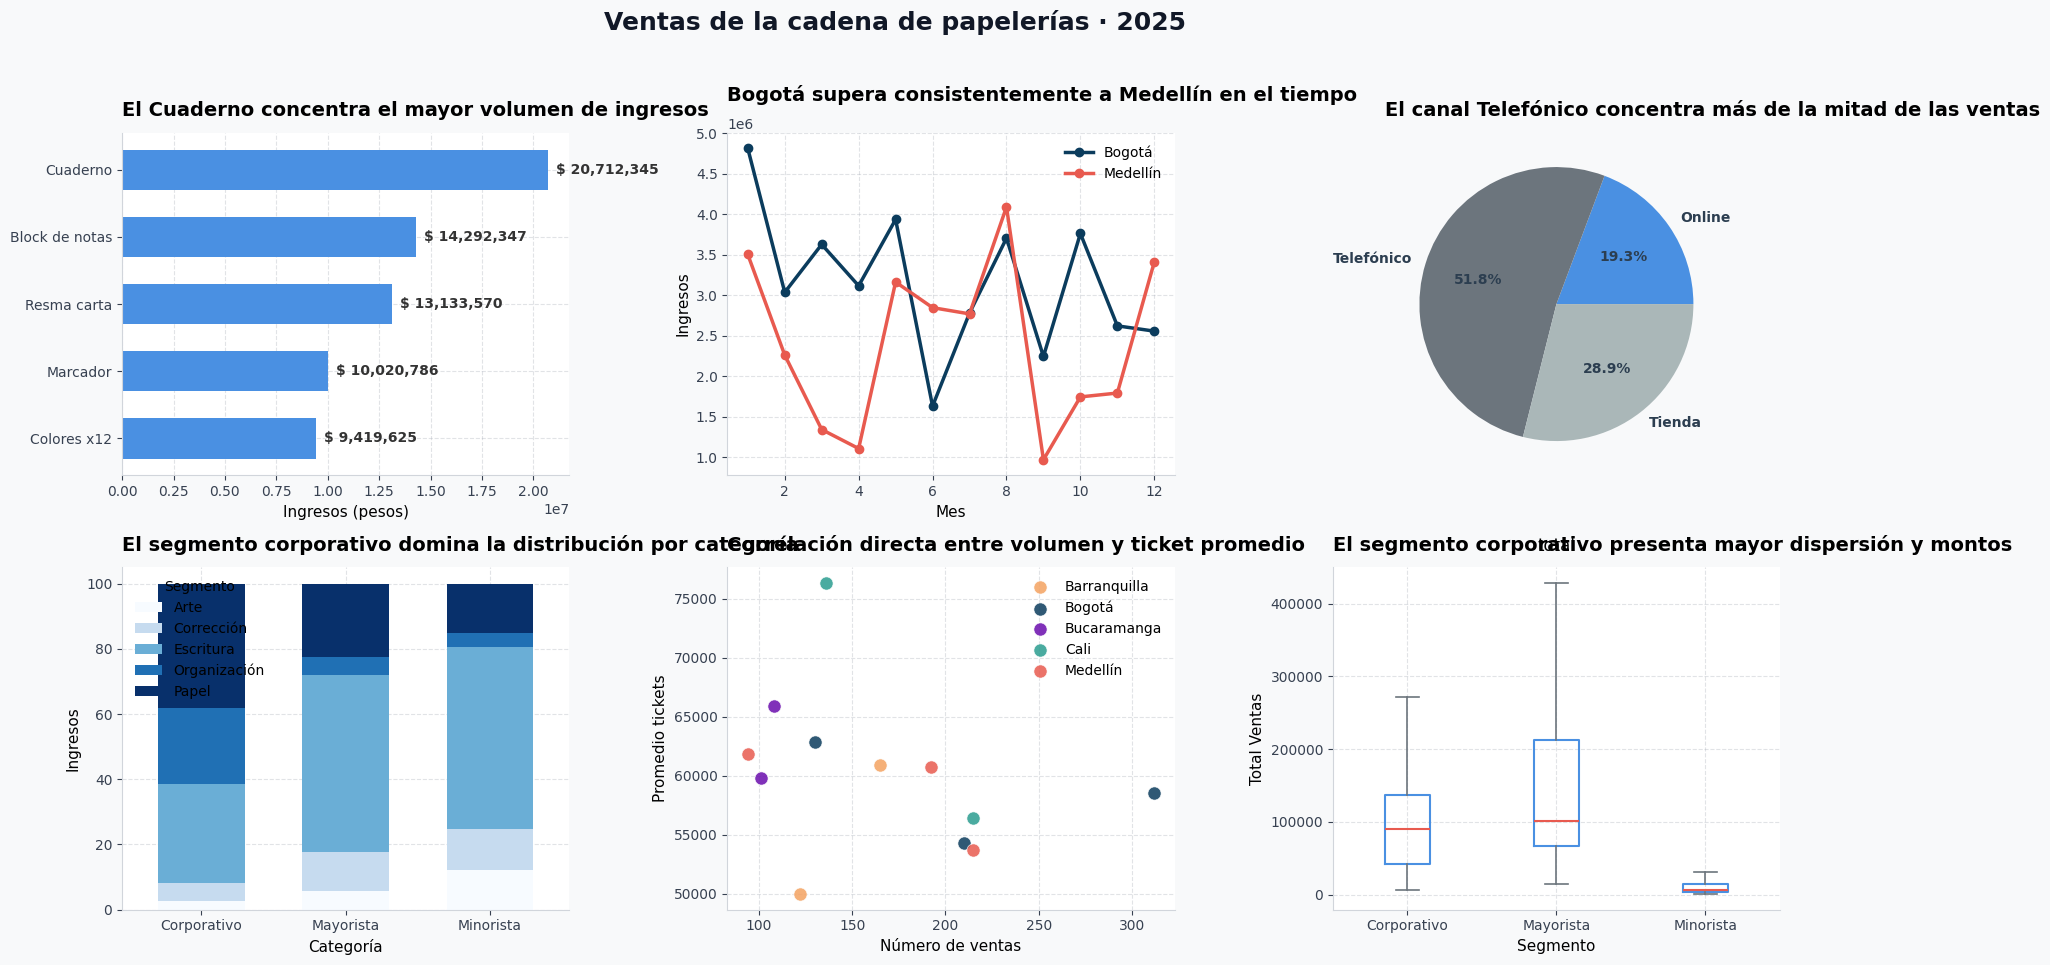

In [136]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Configuración general de la figura con fondo gris muy claro y paneles blancos
fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor='#F8F9FA')

# Paleta fija de colores por ciudad (solo para línea y dispersión)
ciudad_colores = {
    'Bogotá': '#0B3C5D',       # Azul oscuro
    'Medellín': '#E85A4F',     # Naranja
    'Cali': '#2A9D8F',         # Verde
    'Barranquilla': '#F4A261', # Amarillo/Ámbar
    'Bucaramanga': '#6A0DAD'   # Violeta
}

# ---------------------------------------------------------
# Fila 0, Columna 0: Top Productos (Barras horizontales)
# ---------------------------------------------------------
ax0 = axs[0, 0]
top_prod_sorted = top_productos.sort_values()
top_prod_sorted.plot(kind='barh', ax=ax0, color='#4A90E2', width=0.6)
ax0.set_title("El Cuaderno concentra el mayor volumen de ingresos", fontsize=14, fontweight='bold', loc='left', pad=12)
ax0.set_xlabel("Ingresos (pesos)", fontsize=11)
ax0.set_ylabel("", fontsize=11)

# Etiquetas de valores sobre las barras
for p in ax0.patches:
    width = p.get_width()
    ax0.annotate(f'$ {width:,.0f}',
                 (width, p.get_y() + p.get_height() / 2),
                 xytext=(6, 0), textcoords='offset points',
                 ha='left', va='center', fontsize=10, color='#333333', fontweight='bold')

# ---------------------------------------------------------
# Fila 0, Columna 1: Ingresos mes a mes (Bogotá vs. Medellín)
# ---------------------------------------------------------
ax1 = axs[0, 1]
colores_linea = [ciudad_colores.get(col, '#333333') for col in ing_mes_ciudad.columns]
ing_mes_ciudad.plot(kind='line', ax=ax1, marker="o", linewidth=2.5, markersize=6, color=colores_linea)
ax1.set_title("Bogotá supera consistentemente a Medellín en el tiempo", fontsize=14, fontweight='bold', loc='left', pad=12)
ax1.set_xlabel("Mes", fontsize=11)
ax1.set_ylabel("Ingresos", fontsize=11)
ax1.legend(frameon=False, fontsize=10)

# ---------------------------------------------------------
# Fila 0, Columna 2: Canal de venta (Pie chart)
# ---------------------------------------------------------
ax2 = axs[0, 2]
ing_canal.plot(kind='pie', ax=ax2, autopct="%1.1f%%", ylabel="",
               colors=['#4A90E2', '#6C757D', '#AAB7B8', '#D5DBDB'],
               textprops={'fontsize': 10, 'color': '#2C3E50', 'weight': 'bold'})
ax2.set_title("El canal Telefónico concentra más de la mitad de las ventas", fontsize=14, fontweight='bold', loc='left', pad=12)

# ---------------------------------------------------------
# Fila 1, Columna 0: Segmento por categoría (Barras apiladas)
# ---------------------------------------------------------
ax3 = axs[1, 0]
tabla_seg_cat.plot(kind='bar', stacked=True, ax=ax3, colormap='Blues', width=0.6)
ax3.set_title("El segmento corporativo domina la distribución por categoría", fontsize=14, fontweight='bold', loc='left', pad=12)
ax3.set_xlabel("Categoría", fontsize=11)
ax3.set_ylabel("Ingresos", fontsize=11)
ax3.legend(frameon=False, fontsize=10, title="Segmento")
ax3.tick_params(axis='x', rotation=0)

# ---------------------------------------------------------
# Fila 1, Columna 1: Productividad de vendedores (Dispersión)
# ---------------------------------------------------------
ax4 = axs[1, 1]
for ciudad, grupo in vend.groupby("ciudad"):
    color_ciudad = ciudad_colores.get(ciudad, '#333333')
    ax4.scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, s=90, color=color_ciudad, alpha=0.85, edgecolors='white', linewidths=0.5)
ax4.set_xlabel("Número de ventas", fontsize=11)
ax4.set_ylabel("Promedio tickets", fontsize=11)
ax4.set_title("Correlación directa entre volumen y ticket promedio", fontsize=14, fontweight='bold', loc='left', pad=12)
ax4.legend(frameon=False, fontsize=10, loc='best')

# ---------------------------------------------------------
# Fila 1, Columna 2: Ventas por segmento (Boxplot)
# ---------------------------------------------------------
ax5 = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax5,
             boxprops=dict(color='#4A90E2', linewidth=1.5),
             medianprops=dict(color='#E85A4F', linewidth=1.5),
             whiskerprops=dict(color='#6C757D', linewidth=1.2),
             capprops=dict(color='#6C757D', linewidth=1.2))
ax5.set_title("El segmento corporativo presenta mayor dispersión y montos", fontsize=14, fontweight='bold', loc='left', pad=12)
ax5.set_xlabel("Segmento", fontsize=11)
ax5.set_ylabel("Total Ventas", fontsize=11)
ax5.get_figure().suptitle("")

# ---------------------------------------------------------
# Limpieza visual general y estilos para todos los subplots
# ---------------------------------------------------------
for ax in axs.flat:
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#D1D5DB')
    ax.spines['bottom'].set_color('#D1D5DB')
    ax.grid(True, linestyle='--', alpha=0.3, color='#9CA3AF', zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors='#374151', labelsize=10)

# Título general ejecutivo de la figura y ajuste de diseño
fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18, fontweight='bold', color='#111827', y=0.96)
plt.tight_layout(rect=[0, 0, 1, 0.94])

In [137]:
mostrar("v1")

SyntaxError: unmatched ')' (<string>, line 26)

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [138]:
prompt_v2 = prompt_v1 + """

AJUSTES: Estoy partiendo de la figura de la versión 1 y vi estos problemas. Corrígelos sin cambiar los datos, los 6 gráficos ni su posición en la cuadrícula 2 × 3:

1. TÍTULOS QUE SE CHOCAN. Los títulos de algunos gráficos se pisan o se cortan con los de los gráficos vecinos. Usa una tipografía sans-serif más legible (por ejemplo DejaVu Sans), reduce el tamaño de los títulos a 11 en negrita, divide los títulos largos en dos líneas y deja espacio entre los gráficos con plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=2, w_pad=2). Todos los títulos deben leerse completos.

2. RESPETA MIS TÍTULOS. En la versión 1 cambiaste mis títulos por otros inventados. Esta instrucción reemplaza lo que dice la sección TÍTULOS del prompt anterior: no escribas conclusiones propias. Usa exactamente estos títulos, uno por gráfico, sin cambiarlos:
- Barras de productos: "Gráfico de barras del total de ingresos por cada producto"
- Líneas: "Ingresos mes a mes: Bogotá vs. Medellín"
- Pie: "¿Por qué canal se vende más?"
- Barras apiladas: "¿Cada segmento compra lo mismo?"
- Dispersión: "Productividad de los vendedores"
- Cajas: "¿Qué tan grandes son las ventas de cada segmento?"

3. ETIQUETAS DE LAS BARRAS APILADAS. Están cruzadas: el eje X debe decir "Segmento", el eje Y "% de las ventas" y la leyenda debe tener el título "Categoría".

4. FORMATO DE NÚMEROS. Aplica el formato compacto que pedí: "$ 20 M" en los ejes de ingresos y en los valores sobre las barras, y "$ 100 mil" en los ejes de las cajas y de la dispersión. Elimina las notaciones como 1e7 o 1e6.
"""

print(prompt_v2)


PÚBLICO Y OBJETIVO: La figura será presentada a la gerente de compras o a la dirección regional. Su propósito es facilitar la toma de decisiones estratégicas sobre el desempeño de las cinco ciudades, identificar cuáles requieren mayor atención y definir dónde priorizar compras, recursos o acciones de mejora.

PALETA Y TIPOGRAFÍA: Utiliza un diseño profesional, moderno y ejecutivo, con fondo gris muy claro y paneles blancos. Usa un color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Estos colores solo se usan en el gráfico de líneas y en la dispersión; en los otros cuatro gráficos usa una paleta neutra (grises y azules suaves) que no coincida con los colores de ciudad. Fuente sans-serif; títulos en negrita y alineados a la izquierda. Tamaños: títulos de los gráficos 14, etiquetas de ejes 11, valores sobre las barras 10 y título general 18.

TÍTULOS: Cada gráfico debe tener un título que comunique su principal conclusión, 

In [139]:
%%writefile figura_v2.py
# Pega aquí el código que te devolvió la IA para la versión 2
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Configuración general de la figura con fondo gris muy claro y paneles blancos
fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor='#F8F9FA')

# Paleta fija de colores por ciudad (solo para línea y dispersión)
ciudad_colores = {
    'Bogotá': '#0B3C5D',       # Azul oscuro
    'Medellín': '#E85A4F',     # Naranja
    'Cali': '#2A9D8F',         # Verde
    'Barranquilla': '#F4A261', # Amarillo/Ámbar
    'Bucaramanga': '#6A0DAD'   # Violeta
}

# ---------------------------------------------------------
# Fila 0, Columna 0: Top Productos (Barras horizontales)
# ---------------------------------------------------------
ax0 = axs[0, 0]
top_prod_sorted = top_productos.sort_values()
top_prod_sorted.plot(kind='barh', ax=ax0, color='#4A90E2', width=0.6)
ax0.set_title("Gráfico de barras del total de ingresos por cada producto", fontsize=11, fontweight='bold', loc='left', pad=10)
ax0.set_xlabel("Ingresos (pesos)", fontsize=11)
ax0.set_ylabel("", fontsize=11)

# Etiquetas de valores sobre las barras
for p in ax0.patches:
    width = p.get_width()
    ax0.annotate(f'$ {width:,.0f}',
                 (width, p.get_y() + p.get_height() / 2),
                 xytext=(6, 0), textcoords='offset points',
                 ha='left', va='center', fontsize=10, color='#333333', fontweight='bold')

# ---------------------------------------------------------
# Fila 0, Columna 1: Ingresos mes a mes (Bogotá vs. Medellín)
# ---------------------------------------------------------
ax1 = axs[0, 1]
colores_linea = [ciudad_colores.get(col, '#333333') for col in ing_mes_ciudad.columns]
ing_mes_ciudad.plot(kind='line', ax=ax1, marker="o", linewidth=2.5, markersize=6, color=colores_linea)
ax1.set_title("Ingresos mes a mes: Bogotá vs. Medellín", fontsize=11, fontweight='bold', loc='left', pad=10)
ax1.set_xlabel("Mes", fontsize=11)
ax1.set_ylabel("Ingresos", fontsize=11)
ax1.legend(frameon=False, fontsize=10)

# ---------------------------------------------------------
# Fila 0, Columna 2: Canal de venta (Pie chart)
# ---------------------------------------------------------
ax2 = axs[0, 2]
ing_canal.plot(kind='pie', ax=ax2, autopct="%1.1f%%", ylabel="",
               colors=['#4A90E2', '#6C757D', '#AAB7B8', '#D5DBDB'],
               textprops={'fontsize': 10, 'color': '#2C3E50', 'weight': 'bold'})
ax2.set_title("¿Por qué canal se vende más?", fontsize=11, fontweight='bold', loc='left', pad=10)

# ---------------------------------------------------------
# Fila 1, Columna 0: Segmento por categoría (Barras apiladas)
# ---------------------------------------------------------
ax3 = axs[1, 0]
tabla_seg_cat.plot(kind='bar', stacked=True, ax=ax3, colormap='Blues', width=0.6)
ax3.set_title("¿Cada segmento compra lo mismo?", fontsize=11, fontweight='bold', loc='left', pad=10)
ax3.set_xlabel("Categoría", fontsize=11)
ax3.set_ylabel("Ingresos", fontsize=11)
ax3.legend(frameon=False, fontsize=10, title="Segmento")
ax3.tick_params(axis='x', rotation=0)

# ---------------------------------------------------------
# Fila 1, Columna 1: Productividad de vendedores (Dispersión)
# ---------------------------------------------------------
ax4 = axs[1, 1]
for ciudad, grupo in vend.groupby("ciudad"):
    color_ciudad = ciudad_colores.get(ciudad, '#333333')
    ax4.scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, s=90, color=color_ciudad, alpha=0.85, edgecolors='white', linewidths=0.5)
ax4.set_xlabel("Número de ventas", fontsize=11)
ax4.set_ylabel("Promedio tickets", fontsize=11)
ax4.set_title("Productividad de los vendedores", fontsize=11, fontweight='bold', loc='left', pad=10)
ax4.legend(frameon=False, fontsize=10, loc='best')

# ---------------------------------------------------------
# Fila 1, Columna 2: Ventas por segmento (Boxplot)
# ---------------------------------------------------------
ax5 = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax5,
             boxprops=dict(color='#4A90E2', linewidth=1.5),
             medianprops=dict(color='#E85A4F', linewidth=1.5),
             whiskerprops=dict(color='#6C757D', linewidth=1.2),
             capprops=dict(color='#6C757D', linewidth=1.2))
ax5.set_title("¿Qué tan grandes son las ventas de cada segmento?", fontsize=11, fontweight='bold', loc='left', pad=10)
ax5.set_xlabel("Segmento", fontsize=11)
ax5.set_ylabel("Total Ventas", fontsize=11)
ax5.get_figure().suptitle("")

# ---------------------------------------------------------
# Limpieza visual general y estilos para todos los subplots
# ---------------------------------------------------------
for ax in axs.flat:
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#D1D5DB')
    ax.spines['bottom'].set_color('#D1D5DB')
    ax.grid(True, linestyle='--', alpha=0.3, color='#9CA3AF', zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors='#374151', labelsize=10)

# Título general ejecutivo de la figura y ajuste de diseño con mayor espacio vertical (hspace/wspace)
fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=16, fontweight='bold', color='#111827', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93], hspace=0.4, wspace=0.3)

Overwriting figura_v2.py


TypeError: tight_layout() got an unexpected keyword argument 'hspace'

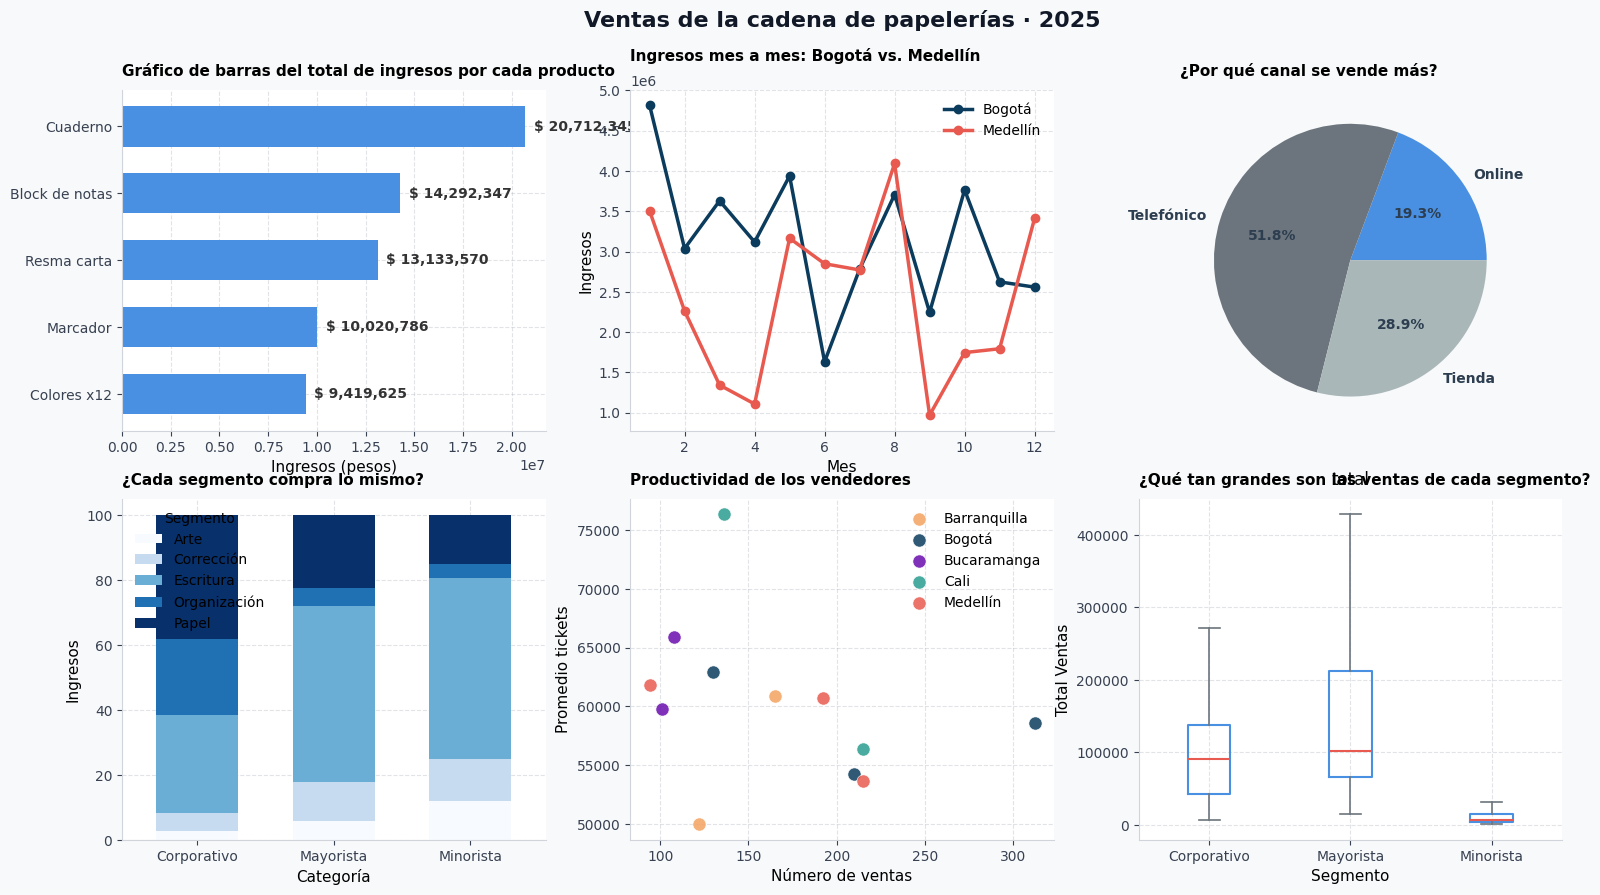

In [140]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [141]:
prompt_v3 = prompt_v2 + """

AJUSTES FINALES: Estoy partiendo del código de la versión 2. Corrígelo sin cambiar los datos, los 6 gráficos ni su posición en la cuadrícula 2 × 3:

1. TÍTULOS CON CONCLUSIÓN REAL. Los títulos volvieron a ser descriptivos y deben decir la conclusión, en 2 líneas (usa \\n) y con fontsize=14 en negrita, alineados a la izquierda. Calcula los valores desde mis tablas; no los escribas a mano:
- Barras de productos: "{producto líder} lidera los ingresos con {valor en millones} M de pesos".
- Líneas: "Bogotá supera a Medellín en {n} de 12 meses", donde n es el número de meses en que Bogotá vende más.
- Pie: "Telefónico concentra el {porcentaje} % de los ingresos".
- Barras apiladas: "Corporativo compra más Papel; los demás, más Escritura".
- Dispersión: "Más ventas no implica un ticket promedio más alto" (la correlación entre n_ventas y ticket_prom es negativa).
- Cajas: "Mayorista tiene las ventas más altas y más dispersas".
No inventes otras conclusiones.

2. ETIQUETAS DE LAS BARRAS APILADAS. Están cruzadas: el eje X debe decir "Segmento", el eje Y "% de las ventas" (son porcentajes, no ingresos) y la leyenda debe tener el título "Categoría". Coloca la leyenda debajo del gráfico, en una sola fila (ncol=5), sin marco y sin tapar las barras.

3. FORMATO DE NÚMEROS. Usa FuncFormatter: en las barras de productos y en las líneas, "$ 20 M" (en las líneas con 1 decimal, para que no se repitan etiquetas); en las cajas y en la dispersión, "$ 100 mil". Los valores sobre las barras deben ir en el mismo formato (por ejemplo "$ 20.7 M"). Etiquetas de ejes en pesos: "Ingresos (pesos)", "Ticket promedio (pesos)" y "Valor de la venta (pesos)". En las líneas, muestra los meses del 1 al 12 en el eje X.

4. COLORES. Medellín debe verse naranja (#F28E2B) y Barranquilla amarillo (#EDC948); Bogotá #1F3A5F, Cali #2A9D8F, Bucaramanga #7B2D8E. En el pie usa grises, con el canal Telefónico en el gris más oscuro.

5. ERRORES TÉCNICOS. plt.tight_layout() no acepta hspace ni wspace: quita esos argumentos y usa solo rect=[0, 0, 1, 0.95]. En el boxplot, pandas deja un título automático "total" que queda encimado: bórralo con ax.set_title("", loc="center") antes de poner el título propio. Quita también el título automático general con plt.suptitle("") antes del suptitle final, de tamaño 18 en negrita.

6. LIMPIEZA. Sin cuadrícula en el pie. Todo lo demás de la limpieza visual queda igual.
"""

print(prompt_v3)
# print(prompt_v3)


PÚBLICO Y OBJETIVO: La figura será presentada a la gerente de compras o a la dirección regional. Su propósito es facilitar la toma de decisiones estratégicas sobre el desempeño de las cinco ciudades, identificar cuáles requieren mayor atención y definir dónde priorizar compras, recursos o acciones de mejora.

PALETA Y TIPOGRAFÍA: Utiliza un diseño profesional, moderno y ejecutivo, con fondo gris muy claro y paneles blancos. Usa un color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Estos colores solo se usan en el gráfico de líneas y en la dispersión; en los otros cuatro gráficos usa una paleta neutra (grises y azules suaves) que no coincida con los colores de ciudad. Fuente sans-serif; títulos en negrita y alineados a la izquierda. Tamaños: títulos de los gráficos 14, etiquetas de ejes 11, valores sobre las barras 10 y título general 18.

TÍTULOS: Cada gráfico debe tener un título que comunique su principal conclusión, 

In [142]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


In [143]:
%%writefile figura_v3.py
# Pega aquí el código que te devolvió la IA para la versión 3
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Colores ----------
ciudad_colores = {
    "Bogotá": "#1F3A5F",        # azul oscuro
    "Medellín": "#F28E2B",      # naranja
    "Cali": "#2A9D8F",          # verde
    "Barranquilla": "#EDC948",  # amarillo
    "Bucaramanga": "#7B2D8E",   # violeta
}
azul_neutro = "#5B8DB8"
gris_neutro = ["#AAB7B8", "#6C757D", "#D5DBDB"]  # Online, Telefónico (más oscuro), Tienda

# ---------- Formatos de números ----------
def millones(x, pos=None):
    return f"$ {x/1e6:,.0f} M"
def millones1(x, pos=None):
    return f"$ {x/1e6:,.1f} M"

# ---------- Datos que se usan en los títulos (salen de TUS tablas) ----------
meses_bog = int((ing_mes_ciudad["Bogotá"] > ing_mes_ciudad["Medellín"]).sum())
pct_tel = ing_canal["Telefónico"] / ing_canal.sum() * 100
lider = top_productos.idxmax()
corr = vend["n_ventas"].corr(vend["ticket_prom"])

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor="#F4F5F7")
TIT = dict(fontsize=14, fontweight="bold", loc="left", pad=12)

# ---- [0,0] Top productos ----
ax = axs[0, 0]
top_productos.sort_values().plot.barh(ax=ax, color=azul_neutro, width=0.6)
ax.set_title(f"{lider} lidera los ingresos\ncon {top_productos.max()/1e6:,.1f} M de pesos", **TIT)
ax.set_xlabel("Ingresos (pesos)", fontsize=11)
ax.set_ylabel("")
ax.xaxis.set_major_formatter(FuncFormatter(millones))
ax.set_xlim(0, top_productos.max() * 1.25)
for p in ax.patches:
    ax.annotate(millones1(p.get_width()), (p.get_width(), p.get_y() + p.get_height()/2),
                xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=10, fontweight="bold", color="#333333")

# ---- [0,1] Líneas Bogotá vs Medellín ----
ax = axs[0, 1]
cols = [ciudad_colores[c] for c in ing_mes_ciudad.columns]
ing_mes_ciudad.plot.line(ax=ax, marker="o", linewidth=2.5, markersize=6, color=cols)
ax.set_title(f"Bogotá supera a Medellín\nen {meses_bog} de 12 meses", **TIT)
ax.set_xlabel("Mes", fontsize=11)
ax.set_ylabel("Ingresos (pesos)", fontsize=11)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(FuncFormatter(millones1))
ax.legend(frameon=False, fontsize=10, title="")

# ---- [0,2] Pie de canales ----
ax = axs[0, 2]
ing_canal.plot.pie(ax=ax, autopct="%1.1f%%", ylabel="", colors=gris_neutro,
                   textprops={"fontsize": 10, "color": "#2C3E50", "weight": "bold"})
ax.set_title(f"Telefónico concentra el\n{pct_tel:.1f} % de los ingresos", **TIT)

# ---- [1,0] Barras apiladas segmento x categoría ----
ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, colormap="Blues", width=0.6)
ax.set_title("Corporativo compra más Papel;\nlos demás, más Escritura", **TIT)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("% de las ventas", fontsize=11)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Categoría", frameon=False, fontsize=9, ncol=5,
          loc="upper center", bbox_to_anchor=(0.5, -0.22))

# ---- [1,1] Dispersión vendedores ----
ax = axs[1, 1]
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=90,
               color=ciudad_colores[ciudad], alpha=0.9, edgecolors="white", linewidths=0.6)
ax.set_title("Más ventas no implica\nun ticket promedio más alto", **TIT)
ax.set_xlabel("Número de ventas", fontsize=11)
ax.set_ylabel("Ticket promedio (pesos)", fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"$ {x/1e3:,.0f} mil"))
ax.legend(frameon=False, fontsize=10, loc="upper right")

# ---- [1,2] Cajas por segmento (2º semestre) ----
ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax,
             boxprops=dict(color=azul_neutro, linewidth=1.5),
             medianprops=dict(color="#C0392B", linewidth=1.8),
             whiskerprops=dict(color="#6C757D"), capprops=dict(color="#6C757D"))
ax.set_title("", loc="center")          # borra el título automático "total"
ax.set_title("Mayorista tiene las ventas\nmás altas y más dispersas", **TIT)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("Valor de la venta (pesos)", fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"$ {x/1e3:,.0f} mil"))

# ---- Limpieza visual general ----
for a in axs.flat:
    a.set_facecolor("white")
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_color("#D1D5DB")
    a.spines["bottom"].set_color("#D1D5DB")
    a.grid(True, linestyle="--", alpha=0.3, color="#9CA3AF")
    a.set_axisbelow(True)
    a.tick_params(colors="#374151", labelsize=10)
axs[0, 2].grid(False)   # el pie no lleva cuadrícula

plt.suptitle("")  # evita el título automático del boxplot
fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18, fontweight="bold", y=0.985)
plt.tight_layout(rect=[0, 0, 1, 0.95])

Overwriting figura_v3.py


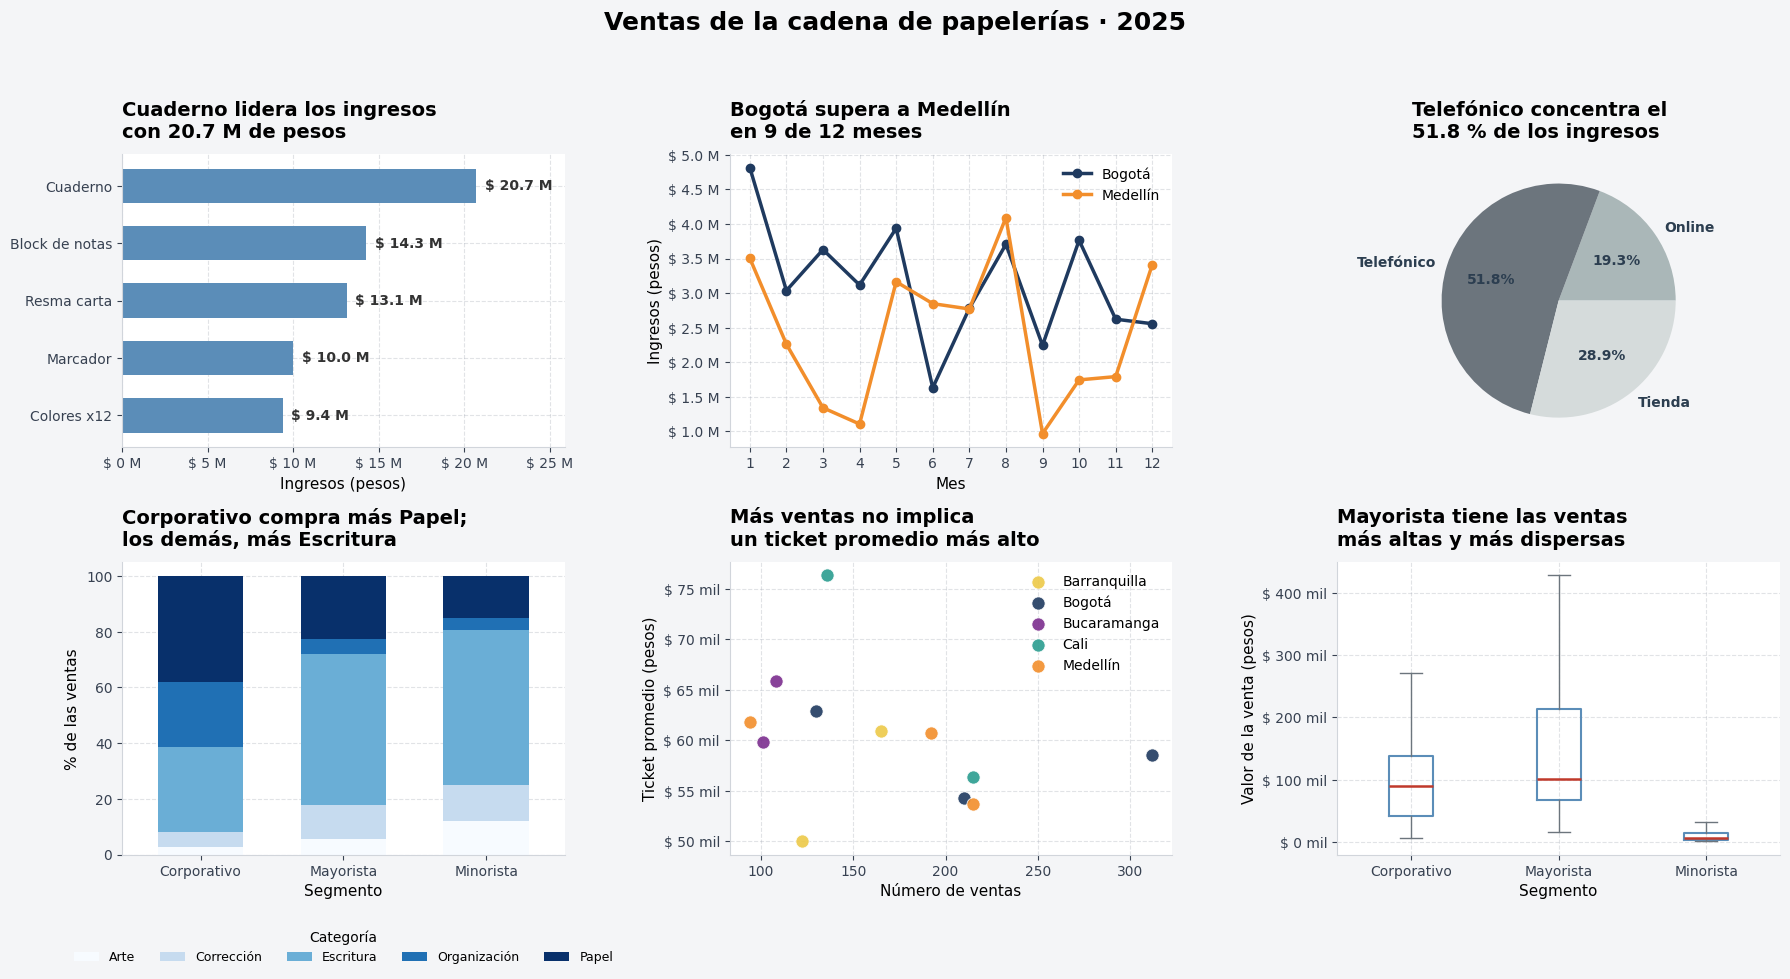

In [144]:
mostrar("v3")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [145]:
figura_elegida = "v3"

hallazgos = [
    "El Cuaderno es el producto con más ingresos: $ 20.7 M, por encima del Block de notas ($ 14.3 M).",
    "El canal Telefónico concentra el 51.8 % de los ingresos de la cadena.",
    "Bogotá vende más que Medellín en 9 de los 12 meses de 2025.",
]

In [146]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

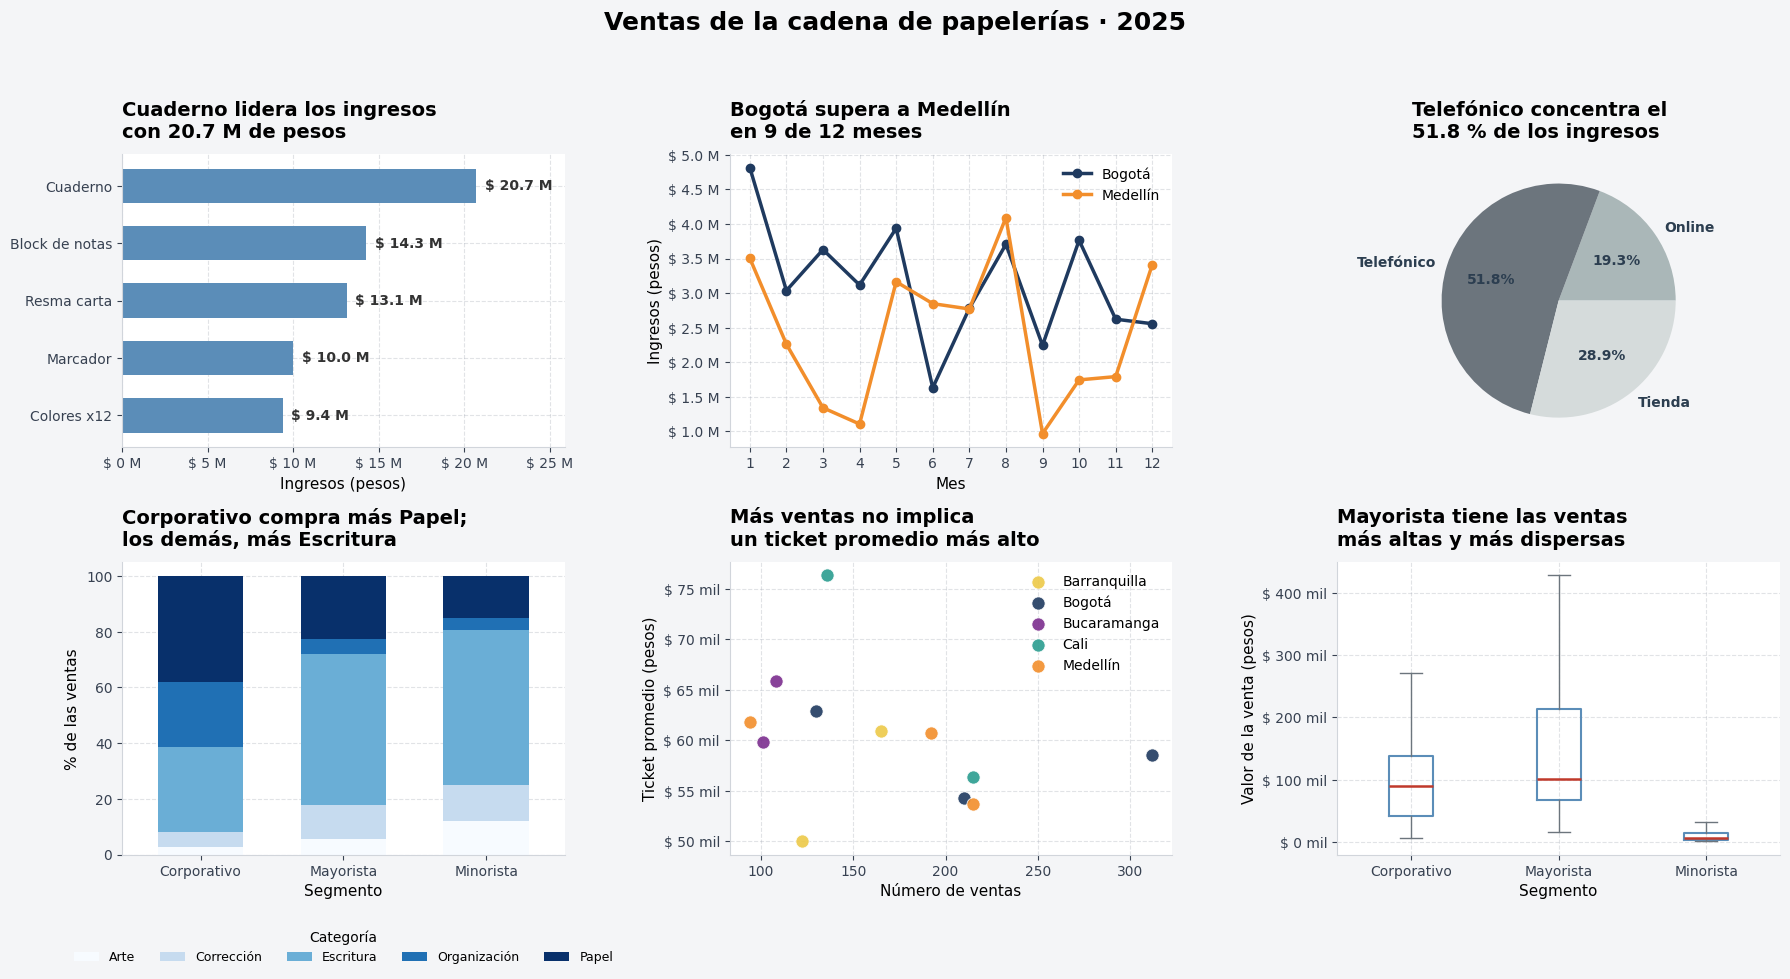

Hallazgos:
• El Cuaderno es el producto con más ingresos: $ 20.7 M, por encima del Block de notas ($ 14.3 M).
• El canal Telefónico concentra el 51.8 % de los ingresos de la cadena.
• Bogotá vende más que Medellín en 9 de los 12 meses de 2025.


In [147]:
mostrar("v3")

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.